# Heart Disease Prediction — Improved Machine Learning Project

A revised version of a 2022 college project. This notebook compares classification models using a deduplicated public dataset and leakage-safe preprocessing. **Educational demonstration only; not a clinical diagnostic tool.**

**Dataset:** Kaggle *Heart Disease Dataset* (`johnsmith88/heart-disease-dataset`). Download `heart.csv` and upload it to Colab before running. The source dataset contains 1,025 rows, including 723 duplicate rows.

## 1. Load and inspect the data

In [14]:
from google.colab import files
uploaded = files.upload()

Saving archive.zip to archive.zip


In [15]:
import os
print(os.listdir('/content'))

['.config', 'drive', 'archive.zip', '.ipynb_checkpoints', 'sample_data']


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Upload heart.csv to the Colab session, or place it alongside this notebook.
heart_data = pd.read_csv('/content/archive.zip', compression='zip')
print(heart_data.shape)
print('Original shape:', heart_data.shape)
print('Missing values:', heart_data.isna().sum().sum())
print('Duplicate rows:', heart_data.duplicated().sum())
display(heart_data.head())

(1025, 14)
Original shape: (1025, 14)
Missing values: 0
Duplicate rows: 723


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 2. Remove duplicates and explore the target

Duplicate removal is performed **before** splitting to avoid identical records appearing in training and testing.

Unique records: 302
Target distribution:
target
0    138
1    164
Name: count, dtype: int64


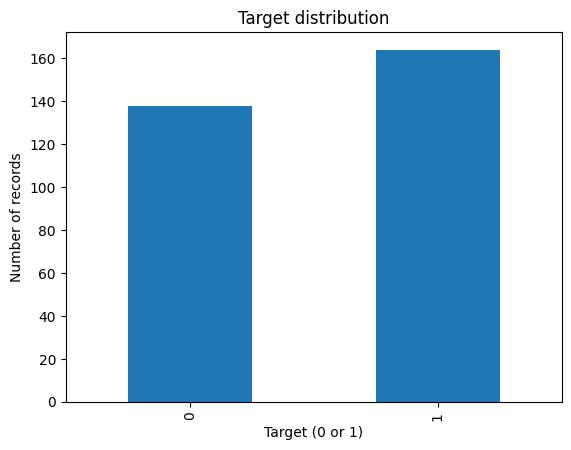

In [17]:
heart_clean = heart_data.drop_duplicates().copy()
X = heart_clean.drop(columns='target')
y = heart_clean['target']
print('Unique records:', len(heart_clean))
print('Target distribution:')
print(y.value_counts().sort_index())
y.value_counts().sort_index().plot(kind='bar', title='Target distribution')
plt.xlabel('Target (0 or 1)')
plt.ylabel('Number of records')
plt.show()

## 3. Train/test split

Use the same stratified 80/20 split for all baseline models. Preprocessing is fitted on training data only.

In [18]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print('Train:', len(X_train), '| Test:', len(X_test))

Train: 241 | Test: 61


## 4. Baseline models

Compare Logistic Regression, Naive Bayes, KNN (K=12), and Random Forest on the same test set.

In [19]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Naive Bayes': Pipeline([
        ('scaler', StandardScaler()), ('model', GaussianNB())
    ]),
    'KNN (K=12)': Pipeline([
        ('scaler', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=12))
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=5, random_state=42
    )
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

## 5. Improved KNN

Scale continuous variables, one-hot encode categorical variables, and tune the number of neighbors **using training data only**.

In [20]:
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_features),
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

knn_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

knn_grid = {'classifier__n_neighbors': [3, 5, 7, 9, 11, 12, 15, 17, 19, 21]}
knn_search = GridSearchCV(knn_pipeline, knn_grid, cv=5, scoring='accuracy', n_jobs=-1)
knn_search.fit(X_train, y_train)
predictions['Improved KNN'] = knn_search.predict(X_test)
print('Best K:', knn_search.best_params_['classifier__n_neighbors'])
print('Training CV accuracy:', round(knn_search.best_score_ * 100, 2), '%')

Best K: 5
Training CV accuracy: 83.82 %


## 6. Compare test-set results

Precision, recall, and F1 below use target class `1` as the positive class.

In [21]:
results = []
for name, pred in predictions.items():
    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, pred) * 100, 2),
        'Recall (%)': round(recall_score(y_test, pred) * 100, 2),
        'F1 (%)': round(f1_score(y_test, pred) * 100, 2)
    })
results_df = pd.DataFrame(results).sort_values('Accuracy (%)', ascending=False)
display(results_df)
print('Improved KNN classification report:')
print(classification_report(y_test, predictions['Improved KNN']))

,Model,Accuracy (%),Precision (%),Recall (%),F1 (%)
4,Improved KNN,83.61,87.10,81.82,84.38
0,Logistic Regression,80.33,80.00,84.85,82.35
2,KNN (K=12),80.33,80.00,84.85,82.35
1,Naive Bayes,78.69,83.33,75.76,79.37
3,Random Forest,77.05,78.79,78.79,78.79


Improved KNN classification report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83        28
           1       0.87      0.82      0.84        33

    accuracy                           0.84        61
   macro avg       0.84      0.84      0.84        61
weighted avg       0.84      0.84      0.84        61



## 7. Nested cross-validation for improved KNN

Each outer fold is evaluated on data excluded from its inner tuning process. This provides a more defensible performance estimate than choosing a model based only on repeated checks of one test split. **This nested-CV result evaluates KNN, not every model in the table above.**

In [22]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)

nested_search = GridSearchCV(
    knn_pipeline,
    {'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 19]},
    cv=inner_cv,
    scoring='accuracy'
)
nested_scores = cross_val_score(nested_search, X, y, cv=outer_cv, scoring='accuracy')
print('Fold accuracies (%):', np.round(nested_scores * 100, 2))
print('Mean accuracy (%):', round(nested_scores.mean() * 100, 2))
print('Standard deviation (%):', round(nested_scores.std() * 100, 2))

Fold accuracies (%): [80.33 85.25 75.   88.33 75.  ]
Mean accuracy (%): 80.78
Standard deviation (%): 5.37


## 8. Findings and limitations

**Results from the original Colab run:** Improved KNN reached **83.61%** on one 61-record test split; nested five-fold CV averaged **80.78%** (standard deviation **5.37 percentage points**). Random Forest reached **77.05%** on that test split. Re-run the notebook to reproduce results in your environment.

**Limitations:** Only **302 unique records** remain after removing duplicates, so results are sensitive to the split. Multiple model choices were explored using the same held-out test set, so the highest test score is exploratory rather than a fully independent final estimate. Nested CV was performed for improved KNN only; it does not establish that KNN is definitively superior to other algorithms. This dataset and model should not be used for medical decisions.

**Compared with the 2022 college project:** The earlier notebook used all 1,025 rows and different preprocessing/evaluation choices. Its reported accuracy numbers are **not directly comparable** with this cleaned-data version.